<a href="https://colab.research.google.com/github/Dineshkumar-DK19/GCEE-HCL/blob/main/Phase%202%20-%20ML/UNIT%201%20-%20Machine%20Learning/Learning%20Tasks/Supervised%20/Decision_Tree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay



In [8]:
df =pd.read_csv("Pass-Fail Data.csv")
df.head()

,student_id,attendance_pct,homework_pct,midterm_score,study_hours_per_week,pass
0,1,95,92,88,12,1
1,2,88,85,79,10,1
2,3,60,55,58,4,0
3,4,72,70,65,6,1
4,5,40,45,50,3,0


In [9]:
#input
X = df[
    [
        "attendance_pct",
        "homework_pct",
        "midterm_score",
        "study_hours_per_week"
    ]
]


#target
y = df["pass"]  # 0 = Fail, 1 = Pass

In [10]:
# 3. Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [11]:
# 4. Create and train the Decision Tree model
model_dt = DecisionTreeClassifier(random_state=42)
model_dt.fit(X_train, y_train)

DecisionTreeClassifier(random_state=42)

In [12]:
# 5. Predict the test results
y_pred_dt = model_dt.predict(X_test)

# 6. Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("\nClassification Report:\n")
print(classification_report(
    y_test,
    y_pred_dt,
    labels=[0, 1],
    target_names=["Fail", "Pass"],
    zero_division=0
))

Accuracy: 0.95

Classification Report:

              precision    recall  f1-score   support

        Fail       0.89      1.00      0.94         8
        Pass       1.00      0.92      0.96        12

    accuracy                           0.95        20
   macro avg       0.94      0.96      0.95        20
weighted avg       0.96      0.95      0.95        20



Confusion Matrix:

[[ 8  0]
 [ 1 11]]


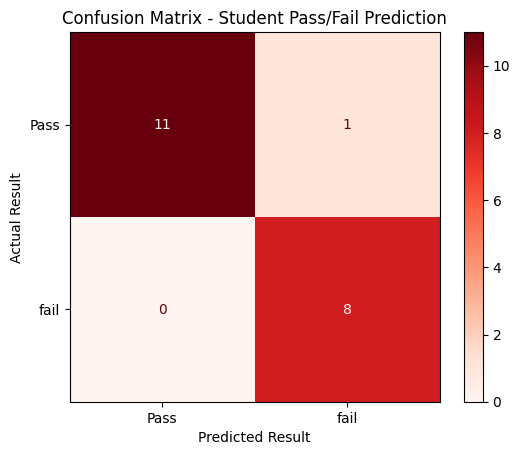

In [17]:
print("Confusion Matrix:\n")
print(confusion_matrix(y_test, y_pred_dt, labels=[0, 1]))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dt,
    labels=[1, 0],
    display_labels=["Pass", "fail"],
    cmap="Reds"
)

plt.title("Confusion Matrix - Student Pass/Fail Prediction")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.show()


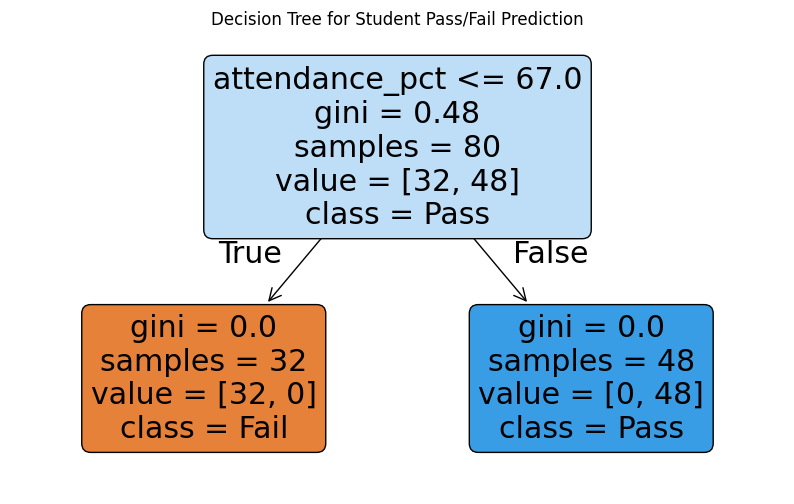

In [21]:
# 8. Visualize the Decision Tree
plt.figure(figsize=(10,6))
plot_tree(
    model_dt,
    feature_names=X.columns,
    class_names=["Fail", "Pass"],
    filled=True,
    rounded=True
)
plt.title("Decision Tree for Student Pass/Fail Prediction")
plt.show()